In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("C:\\Users\\ASUS\\OneDrive\\Desktop\\shanmukha\\Calibo\\data Sets\\Phase_2_dataSets\\diabetes+130-us+hospitals+for+years+1999-2008\\diabetic_data.csv")

ids_mapping = pd.read_csv("C:\\Users\\ASUS\\OneDrive\\Desktop\\shanmukha\\Calibo\\data Sets\\Phase_2_dataSets\\diabetes+130-us+hospitals+for+years+1999-2008\\IDS_mapping.csv")

## understanding the data 

In [3]:
print("Diabetic Dataset:")
print(df.shape)

print("\nIDS Mapping Dataset:")
print(ids_mapping.shape)

Diabetic Dataset:
(101766, 50)

IDS Mapping Dataset:
(67, 2)


In [4]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [5]:
df.tail()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,Down,No,No,No,No,No,Ch,Yes,>30
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,Steady,No,No,No,No,No,No,Yes,NO
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,Down,No,No,No,No,No,Ch,Yes,NO
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,Up,No,No,No,No,No,Ch,Yes,NO
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,No,No,No,NO


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [7]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,NaN,NaN,NaN,165201645.622978,102640295.983457,12522.0,84961194.0,152388987.0,230270887.5,443867222.0
patient_nbr,101766.0,NaN,NaN,NaN,54330400.694947,38696359.346534,135.0,23413221.0,45505143.0,87545949.75,189502619.0
race,101766,6,Caucasian,76099,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,101766,3,Female,54708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,101766,10,[70-80),26068,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weight,101766,10,?,98569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admission_type_id,101766.0,NaN,NaN,NaN,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,NaN,NaN,NaN,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,NaN,NaN,NaN,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,NaN,NaN,NaN,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


In [8]:
print("Total columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(i, col)

Total columns: 50
1 encounter_id
2 patient_nbr
3 race
4 gender
5 age
6 weight
7 admission_type_id
8 discharge_disposition_id
9 admission_source_id
10 time_in_hospital
11 payer_code
12 medical_specialty
13 num_lab_procedures
14 num_procedures
15 num_medications
16 number_outpatient
17 number_emergency
18 number_inpatient
19 diag_1
20 diag_2
21 diag_3
22 number_diagnoses
23 max_glu_serum
24 A1Cresult
25 metformin
26 repaglinide
27 nateglinide
28 chlorpropamide
29 glimepiride
30 acetohexamide
31 glipizide
32 glyburide
33 tolbutamide
34 pioglitazone
35 rosiglitazone
36 acarbose
37 miglitol
38 troglitazone
39 tolazamide
40 examide
41 citoglipton
42 insulin
43 glyburide-metformin
44 glipizide-metformin
45 glimepiride-pioglitazone
46 metformin-rosiglitazone
47 metformin-pioglitazone
48 change
49 diabetesMed
50 readmitted


In [9]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


#### Understand the target distribution

In [10]:
print(df['readmitted'].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


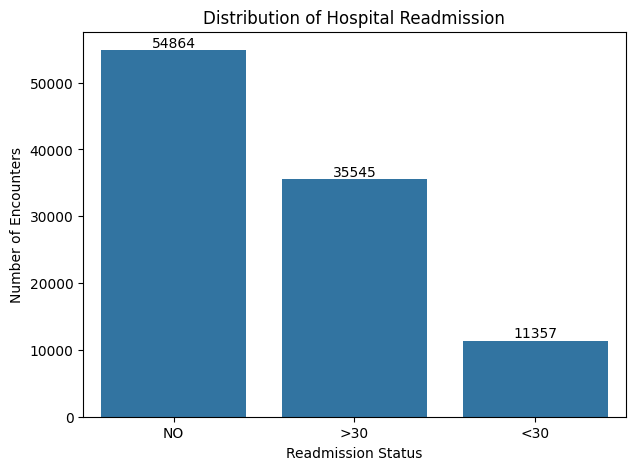

In [12]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='readmitted')

for container in ax.containers:
    ax.bar_label(container, fmt='%d')

plt.title('Distribution of Hospital Readmission')
plt.xlabel('Readmission Status')
plt.ylabel('Number of Encounters')

plt.show()


- **Observation:** The <30 category contains considerably fewer records than the other two categories. This indicates a class imbalance that we must investigate.
- **53.92% of encounters have no readmission.**
- **34.93% are readmitted after 30 days.**
- **Only 11.16% are readmitted within 30 days.**

## Missing analysis 

In [14]:
missing_values = df.isnull().sum()

missing_values

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [15]:
missing_percentage = (missing_values / len(df)) * 100

print(missing_percentage)

encounter_id                 0.000000
patient_nbr                  0.000000
race                         0.000000
gender                       0.000000
age                          0.000000
weight                       0.000000
admission_type_id            0.000000
discharge_disposition_id     0.000000
admission_source_id          0.000000
time_in_hospital             0.000000
payer_code                   0.000000
medical_specialty            0.000000
num_lab_procedures           0.000000
num_procedures               0.000000
num_medications              0.000000
number_outpatient            0.000000
number_emergency             0.000000
number_inpatient             0.000000
diag_1                       0.000000
diag_2                       0.000000
diag_3                       0.000000
number_diagnoses             0.000000
max_glu_serum               94.746772
A1Cresult                   83.277322
metformin                    0.000000
repaglinide                  0.000000
nateglinide 

In [16]:
missing_df = pd.DataFrame({
    'Missing_Values': missing_values,
    'Missing_Percentage': missing_percentage
})

missing_df = missing_df[
    missing_df['Missing_Values'] > 0
].sort_values(by='Missing_Percentage', ascending=False)

missing_df

,Missing_Values,Missing_Percentage
max_glu_serum,96420,94.746772
A1Cresult,84748,83.277322


In [17]:
question_mark_count = df.astype(str).eq('?').sum()

print(question_mark_count)

encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [18]:
question_mark_percentage = (question_mark_count / len(df)) * 100
print(question_mark_percentage)

encounter_id                 0.000000
patient_nbr                  0.000000
race                         2.233555
gender                       0.000000
age                          0.000000
weight                      96.858479
admission_type_id            0.000000
discharge_disposition_id     0.000000
admission_source_id          0.000000
time_in_hospital             0.000000
payer_code                  39.557416
medical_specialty           49.082208
num_lab_procedures           0.000000
num_procedures               0.000000
num_medications              0.000000
number_outpatient            0.000000
number_emergency             0.000000
number_inpatient             0.000000
diag_1                       0.020636
diag_2                       0.351787
diag_3                       1.398306
number_diagnoses             0.000000
max_glu_serum                0.000000
A1Cresult                    0.000000
metformin                    0.000000
repaglinide                  0.000000
nateglinide 

In [19]:
question_mark_df = pd.DataFrame({
    'Question_Mark_Count': question_mark_count,
    'Percentage': question_mark_percentage
})

question_mark_df = question_mark_df[
    question_mark_df['Question_Mark_Count'] > 0
].sort_values(by='Percentage', ascending=False)

question_mark_df

,Question_Mark_Count,Percentage
weight,98569,96.858479
medical_specialty,49949,49.082208
payer_code,40256,39.557416
race,2273,2.233555
diag_3,1423,1.398306
diag_2,358,0.351787
diag_1,21,0.020636


### Observation

From the missing value analysis, I observed that the dataset contains two forms of missing data:

1. **Actual null values**
2. Missing values represented by the **`?`** symbol

Among the columns with actual null values, **`max_glu_serum`** has the highest percentage of missing data (**94.75%**), followed by **`A1Cresult`** (**83.28%**).

For columns where missing values are represented by **`?`**, **`weight`** has the highest proportion of missing records (**96.86%**), followed by **`medical_specialty`** and **`payer_code`**.

These observations indicate that several features have a substantial amount of missing information and should be carefully evaluated before deciding on appropriate preprocessing or imputation techniques.

#### Check unique values

In [20]:
# Check unique values in each column
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

encounter_id: 101766 unique values
patient_nbr: 71518 unique values
race: 6 unique values
gender: 3 unique values
age: 10 unique values
weight: 10 unique values
admission_type_id: 8 unique values
discharge_disposition_id: 26 unique values
admission_source_id: 17 unique values
time_in_hospital: 14 unique values
payer_code: 18 unique values
medical_specialty: 73 unique values
num_lab_procedures: 118 unique values
num_procedures: 7 unique values
num_medications: 75 unique values
number_outpatient: 39 unique values
number_emergency: 33 unique values
number_inpatient: 21 unique values
diag_1: 717 unique values
diag_2: 749 unique values
diag_3: 790 unique values
number_diagnoses: 16 unique values
max_glu_serum: 3 unique values
A1Cresult: 3 unique values
metformin: 4 unique values
repaglinide: 4 unique values
nateglinide: 4 unique values
chlorpropamide: 4 unique values
glimepiride: 4 unique values
acetohexamide: 2 unique values
glipizide: 4 unique values
glyburide: 4 unique values
tolbutamide

#### Inspect categorical values

In [21]:
categorical_columns = [
    'race',
    'gender',
    'weight',
    'payer_code',
    'medical_specialty',
    'max_glu_serum',
    'A1Cresult',
    'change',
    'diabetesMed'
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- race ---
race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

--- gender ---
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

--- weight ---
weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3
Name: count, dtype: int64

--- payer_code ---
payer_code
?     40256
MC    32439
HM     6274
SP     5007
BC     4655
MD     3532
CP     2533
UN     2448
CM     1937
OG     1033
PO      592
DM      549
CH      146
WC      135
OT       95
MP       79
SI       55
FR        1
Name: count, dtype: int64

--- medical_specialty ---
medical_specialty
?                         49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7

#### Inspect medication columns

In [22]:
medication_columns = [
    'metformin', 'repaglinide', 'nateglinide',
    'chlorpropamide', 'glimepiride', 'acetohexamide',
    'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose',
    'miglitol', 'troglitazone', 'tolazamide',
    'insulin', 'glyburide-metformin',
    'glipizide-metformin', 'glimepiride-pioglitazone',
    'metformin-rosiglitazone', 'metformin-pioglitazone'
]

for col in medication_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- metformin ---
metformin
No        81778
Steady    18346
Up         1067
Down        575
Name: count, dtype: int64

--- repaglinide ---
repaglinide
No        100227
Steady      1384
Up           110
Down          45
Name: count, dtype: int64

--- nateglinide ---
nateglinide
No        101063
Steady       668
Up            24
Down          11
Name: count, dtype: int64

--- chlorpropamide ---
chlorpropamide
No        101680
Steady        79
Up             6
Down           1
Name: count, dtype: int64

--- glimepiride ---
glimepiride
No        96575
Steady     4670
Up          327
Down        194
Name: count, dtype: int64

--- acetohexamide ---
acetohexamide
No        101765
Steady         1
Name: count, dtype: int64

--- glipizide ---
glipizide
No        89080
Steady    11356
Up          770
Down        560
Name: count, dtype: int64

--- glyburide ---
glyburide
No        91116
Steady     9274
Up          812
Down        564
Name: count, dtype: int64

--- tolbutamide ---
tolbutamide
No 

#### Inspect diagnosis columns

In [23]:
diagnosis_columns = ['diag_1', 'diag_2', 'diag_3']

for col in diagnosis_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().head(15))
    print("Unique values:", df[col].nunique())
    print("Question marks:", (df[col] == '?').sum())


--- diag_1 ---
diag_1
428      6862
414      6581
786      4016
410      3614
486      3508
427      2766
491      2275
715      2151
682      2042
434      2028
780      2019
996      1967
276      1889
38       1688
250.8    1680
Name: count, dtype: int64
Unique values: 717
Question marks: 21

--- diag_2 ---
diag_2
276       6752
428       6662
250       6071
427       5036
401       3736
496       3305
599       3288
403       2823
414       2650
411       2566
250.02    2074
707       1999
585       1871
584       1649
491       1545
Name: count, dtype: int64
Unique values: 749
Question marks: 358

--- diag_3 ---
diag_3
250       11555
401        8289
276        5175
428        4577
427        3955
414        3664
496        2605
403        2357
585        1992
272        1969
599        1941
?          1423
V45        1389
250.02     1369
707        1360
Name: count, dtype: int64
Unique values: 790
Question marks: 1423


#### Inspect numerical columns

In [24]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nStatistical Summary:")
display(df[numerical_columns].describe().T)

Numerical columns:
['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


Important observations
- number_outpatient, number_emergency, and number_inpatient have minimum values of zero.
- Their maximum values are considerably higher than their typical values.
- num_medications ranges from 1 to 81.
- The numerical features have different scales.

In [25]:
print(ids_mapping.to_string(index=False))

       admission_type_id                                                                                               description
                       1                                                                                                 Emergency
                       2                                                                                                    Urgent
                       3                                                                                                  Elective
                       4                                                                                                   Newborn
                       5                                                                                             Not Available
                       6                                                                                                       NaN
                       7                                                           

In [26]:
id_columns = [
    'admission_type_id',
    'discharge_disposition_id',
    'admission_source_id'
]

for col in id_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().sort_index())


--- admission_type_id ---
admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64

--- discharge_disposition_id ---
discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

--- admission_source_id ---
admission_source_id
1     29565
2      1104
3       187
4      3187
5       855
6      2264
7     57494
8        16
9       125
10        8
11        2
13        1
14        2
17     6781
20      161
22       12
25        2
Name: count, dtype: int64


- **Observation:** Emergency admissions are the most frequent, with 53,990 records. Newborn and Trauma Center categories have very few records.

**Important:** IDs 11, 13, and 14 represent discharge outcomes that require special consideration. We should investigate their relationship with the target before deciding whether to exclude them.

Also, ID 18 has 3,691 records but no description in the mapping file. We must preserve this information rather than invent a description.

- **Observation:** Emergency Room is the most common admission source, accounting for 57,494 records.

#### Investigate discharge disposition against readmission

In [27]:
discharge_readmission = pd.crosstab(
    df['discharge_disposition_id'],
    df['readmitted'],
    margins=True
)

discharge_readmission

readmitted,<30,>30,NO,All
discharge_disposition_id,,,,
1,5602,21517,33115,60234
2,342,668,1118,2128
3,2046,4916,6992,13954
4,104,278,433,815
5,247,350,587,1184
6,1638,5362,5902,12902
7,90,221,312,623
8,15,38,55,108
9,9,2,10,21


In [28]:
discharge_readmission_pct = pd.crosstab(
    df['discharge_disposition_id'],
    df['readmitted'],
    normalize='index'
) * 100

discharge_readmission_pct.round(2)

readmitted,<30,>30,NO
discharge_disposition_id,,,
1,9.30,35.72,54.98
2,16.07,31.39,52.54
3,14.66,35.23,50.11
4,12.76,34.11,53.13
5,20.86,29.56,49.58
6,12.70,41.56,45.74
7,14.45,35.47,50.08
8,13.89,35.19,50.93
9,42.86,9.52,47.62


##### Expired patients(11,19,20)
All 1,652 records in these three categories have NO as their readmission label.

This makes sense because a patient who has died cannot subsequently be readmitted.

##### Hospice patients(13,14)
Unlike the expired categories, hospice categories contain some readmission records.

Therefore, we should not automatically treat hospice patients as equivalent to expired patients.

In [29]:
# Discharge disposition IDs representing expired patients
expired_ids = [11, 19, 20]

# Create a separate dataset
eligible_df = df[
    ~df['discharge_disposition_id'].isin(expired_ids)
].copy()

print("Original dataset shape:", df.shape)
print("Eligible dataset shape:", eligible_df.shape)

print("\nRemoved records:")
print(len(df) - len(eligible_df))

print("\nReadmission distribution after exclusion:")
print(eligible_df['readmitted'].value_counts())

Original dataset shape: (101766, 50)
Eligible dataset shape: (100114, 50)

Removed records:
1652

Readmission distribution after exclusion:
readmitted
NO     53212
>30    35545
<30    11357
Name: count, dtype: int64


### Observation

During the analysis of the **`discharge_disposition_id`** feature, I identified **1,652 records** corresponding to expired patients (disposition IDs **11, 19, and 20**). Since these patients cannot be readmitted after discharge, they were removed from the dataset to ensure the target population accurately reflects patients who are eligible for future readmission.

After excluding these records, the dataset size was reduced to **100,114 encounters**.

I also observed that the target variable is imbalanced. Patients readmitted within **30 days (`<30`)** account for only **11.34%** of the eligible dataset, while the remaining records belong to the majority class. This class imbalance should be considered during model development and evaluation.

#### Investigate patient-level duplicates

In [30]:
# Number of unique patients
unique_patients = eligible_df['patient_nbr'].nunique()

In [31]:
# Number of encounters
total_encounters = len(eligible_df)


In [32]:
# Number of patients with multiple encounters
patient_counts = eligible_df['patient_nbr'].value_counts()

In [33]:
multiple_encounter_patients = (
    patient_counts[patient_counts > 1]
)


In [34]:
print("Total encounters:", total_encounters)
print("Unique patients:", unique_patients)


Total encounters: 100114
Unique patients: 70439


In [35]:
print("Patients with multiple encounters:",len(multiple_encounter_patients))


Patients with multiple encounters: 16483


In [36]:
print("Maximum encounters for one patient:",patient_counts.max())

Maximum encounters for one patient: 40


- We have 100,114 hospital encounters, not 100,114 different patients.
- 16,483 patients have multiple encounters.
- One patient has as many as 40 encounters.

**Important:** These are not duplicate rows. They are separate hospital encounters belonging to the same patient.

- We should use a patient-group-based split so that all encounters belonging to one patient stay in the same dataset.

In [38]:
patient_counts.describe()

count    70439.000000
mean         1.421287
std          1.088970
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
Name: count, dtype: float64

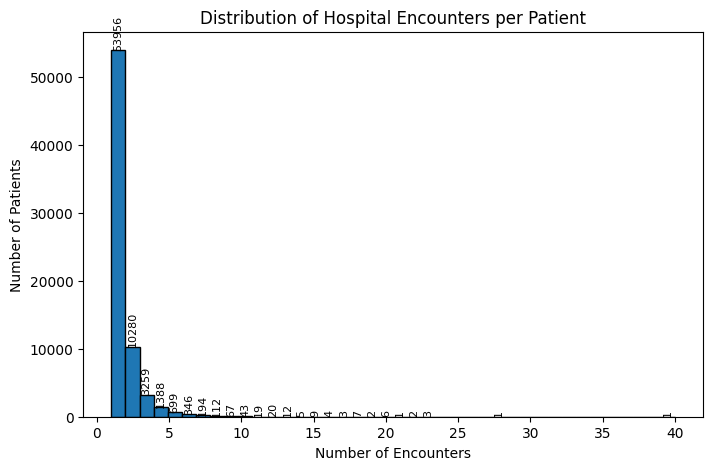

In [40]:
plt.figure(figsize=(8, 5))

counts, bins, patches = plt.hist(
    patient_counts,
    bins=40,
    edgecolor='black'
)

# Add labels on bars
for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            f'{int(count)}',
            ha='center',
            va='bottom',
            fontsize=8,
            rotation=90
        )

plt.title('Distribution of Hospital Encounters per Patient')
plt.xlabel('Number of Encounters')
plt.ylabel('Number of Patients')

plt.show()

From the graph, I can observe:
1. Most patients have only one hospital encounter.
2. The number of patients decreases as the number of encounters increases.
3. A small number of patients have multiple encounters.
4. A few patients have a very high number of encounters, with the maximum reaching 40.
This confirms that the dataset contains repeated encounters for some patients.

### Observation

The distribution of hospital encounters per patient is highly right-skewed. I observed that the majority of patients have only a single hospital encounter, while a relatively small number of patients have multiple encounters recorded in the dataset.

This indicates that several records may belong to the same patient. To prevent data leakage and ensure reliable model evaluation, patient-level grouping should be maintained when creating the train, validation, and test datasets so that encounters from the same patient do not appear across different data splits.